<a href="https://colab.research.google.com/github/RxxOneX/-AI-log-chrome/blob/main/%E5%9F%BA%E5%9B%A0%E6%BC%94%E7%AE%97%E6%B3%95%E6%95%99%E5%AD%B8%E6%AA%94.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

大家有空順便幫我訂閱~\
寫程式可以放著聽故事\
https://runtale.soci.vip/


### 安裝必要的套件

In [ ]:
!pip install finlab
!pip install deap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.4/135.4 kB 2.3 MB/s eta 0:00:00


### 導入必需的套件

In [ ]:
import numpy as npn
import pandas as pd
from deap import base, creator, tools
from functools import reduce
import finlab
import random
import os
import pickle
from tqdm import tqdm
from finlab import data
from finlab.backtest import sim
from finlab.dataframe import FinlabDataFrame
from google.colab import userdata
from google.colab import drive
drive.mount('/content/drive')
#這裡要替換成自己的FinLab VIP token
token = 'FinLab VIP token'
finlab.login(token)

Mounted at /content/drive
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
輸入成功!


### 準備因子

In [ ]:
市值 = data.get('etl:market_value')
close = data.get("price:收盤價")
close_pct_change = close.pct_change()
adj_close = data.get('etl:adj_close')
vol_stock = data.get('price:成交股數')
vol = data.get("price:成交金額")
rev = data.get('monthly_revenue:當月營收')
rev_year_growth = data.get('monthly_revenue:去年同月增減(%)')
rev_month_growth =  data.get('monthly_revenue:上月比較增減(%)')
ma5 = close.average(5)
ma20 = close.average(20)
ma60 = close.average(60)
vol_ma20 = vol.average(20)
vol_stock_ma20 = vol_stock.average(20)
RS = close_pct_change.clip(lower=0).rolling(20).sum() / abs(close_pct_change.clip(upper=0).rolling(20).sum())
RSI = 100 - 100 / (1 + RS)

dataset = {
    '價格動量5': ((close - ma5)/ma5) > 0.05,
    '價格動量20': ((close - ma20)/ma20) > 0.05,
    '價格動量60': ((close - ma60)/ma60) > 0.05,
    '成交股數顯著增加': ((vol_stock - vol_stock_ma20)/vol_stock_ma20) > 0.5,
    '成交金額顯著增加': ((vol - vol_ma20)/vol_ma20) > 0.3,
    '價格波動率低': close_pct_change.rolling(20).std() < 0.02,
    '價格波動率高': close_pct_change.rolling(20).std() > 0.05,
    'RSI': (RSI < 70) & (RSI > 30),
    '月營收年增率10': rev_year_growth > 10,
    '月營收月增率20': rev_month_growth > 20,
    '交易活絡': (vol / 市值) > 0.002,
    '過去5天資金流入': (((close - close.shift(1)) * vol_stock).rolling(5).sum()) > 0,
    '價格突破20日高點': (close / close.shift(1).rolling(20).max()) > 1.02  ,
    '成交量突破20日高點': (vol_stock / vol_stock.shift(1).rolling(20).max()) > 1.5,
    '價格成交量背離' : (np.sign(close - close.shift(5)) * np.sign(vol_stock - vol_stock.shift(5))) >= 0,
    '月營收季節因子' : (rev / ((rev.shift(12) + rev.shift(24) + rev.shift(36))/3)) > 1.1,
    'MA反轉' : (ma5/ma20) > 1,
    '股價營收敏感度' : ((close - close.shift(20)) / (rev - rev.shift(1))) > 0.1,
}

# 將所有的資料轉換成boolean，並確保index是datetime，並且轉換成FinlabDataFrame
for key, value in dataset.items():
    if value.index.dtype == 'O':
        dataset[key] = value.deadline().fillna(False).astype(bool)
    else:
        dataset[key] = value.fillna(False).astype(bool)
    dataset[key] = FinlabDataFrame(dataset[key])

# 把條件數目作為基因長度
individual_size = len(dataset)
# 把dataset的key取出來，之後會用到
keys = list(dataset.keys())

<ipython-input-3-83f868de460f>:3: FutureWarning: The default fill_method='pad' in FinlabDataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  close_pct_change = close.pct_change()


### 自定義Function

In [ ]:
#讀檔用的
def load_data(filename, default_data):
    print(f'讀取 {filename}.pkl...')
    if os.path.exists(filename + '.pkl'):
        with open(filename + '.pkl', 'rb') as f:
            print(f'{filename}.pkl 讀取成功')
            return pickle.load(f)
    print(f'{filename}.pkl 不存在，將使用預設值')
    return default_data
#存檔用的
def save_data(data, filename):
    print(f'保存 {filename}.pkl...')
    with open(filename + '.pkl', 'wb') as f:
        pickle.dump(data, f)
    print(f'{filename}.pkl 保存成功')
# 對選定的基因取交集
def cross_condition(conditions, weight):
    cond_temp = [conditions[i] for i in weight]
    return reduce(lambda i, j: i & j, cond_temp)
# 把基因轉換成條件
def gene_to_RNA(gene, keys):
    return [key for key, g in zip(keys, gene) if g == 1]
# 把條件轉換成基因
def RNA_to_gene(RNA, keys):
    return [1 if key in RNA else 0 for key in keys]

### 利用DEAP建構演算法

In [ ]:
# 設定演算法要求最大值
creator.create("FitnessMax", base.Fitness, weights=(1.0,))
# 設定個體的基因格式為List，並且包含FitnessMax的屬性
creator.create("Individual", list, fitness=creator.FitnessMax)
# 設定toolbox，工具箱用於註冊和管理演算法中使用的各種函數和操作
toolbox = base.Toolbox()
#註冊一個名為"attr_bool"的屬性生成器。使用Python的random.randint函數，生成0或1的隨機整數。
toolbox.register("attr_bool", random.randint, 0, 1)
#註冊一個用於創建個體的函數。使用tools.initRepeat函數重複調用attr_bool函數來創建一個個體。
toolbox.register("individual", tools.initRepeat, creator.Individual, toolbox.attr_bool, n=individual_size)
#註冊一個用於創建整個族群的函數。使用tools.initRepeat函數重複調用toolbox.individual函數來創建一個族群。
toolbox.register("population", tools.initRepeat, list, toolbox.individual)

# 用個體基因計算適應度
def objective(gene,keys):
    RNA = gene_to_RNA(gene,keys)
    position_temp = cross_condition(dataset.copy(), RNA)

    # 檢查每年平均交易次數
    每年平均交易次數 = (abs(position_temp.diff())>0).sum().sum()/(float((position_temp.index.max() - position_temp.index.min()).days//365))
    if 每年平均交易次數 < 50:
        print(f"交易次數過少，每年平均交易次數: {每年平均交易次數}")
        return (0,)

    report = sim(position_temp, resample='M', upload=False, position_limit=1/5, fee_ratio=1.425/1000/3,  trade_at_price='high_low_avg')
    rs = report.get_stats()
    年化報酬率 = round(rs['cagr'] * 100, 3)
    最大回落 = round(rs['max_drawdown'] * 100, 3)
    日索提諾 = round(rs['daily_sortino'], 3)
    fittness = 年化報酬率/abs(最大回落) * 日索提諾
    print(f'{RNA}')
    print(f'年化報酬率: {年化報酬率}%, 最大回落: {最大回落}%, 日索提諾: {日索提諾}, 適應度: {fittness}')
    return (fittness,)

# 註冊一個用於評估整個族群的函數。使用objective函數來評估個體。
toolbox.register("evaluate", objective)
# 註冊一個用於交叉的函數。使用tools.cxUniform函數來實現均勻交叉。
toolbox.register("mate", tools.cxUniform)
# 註冊一個用於突變的函數。使用tools.mutFlipBit函數來實現基因突變。
toolbox.register("mutate", tools.mutFlipBit, indpb=0.05)
# 註冊一個用於選擇的函數。使用tools.selTournament函數來實現錦標賽選擇。
toolbox.register("select", tools.selTournament, tournsize=5)

#評估整個全體的function
def evaluate(offspring, pop, evaled_ind, evaled_ind_empty, keys):
    dict_count = 0
    empty_count = 0
    for idx,ind in enumerate(offspring):
        #先將基因轉換成條件
        RNA = str(gene_to_RNA(ind,keys))
        #如果該個體的適應度還沒被計算過，則計算適應度
        if not ind.fitness.valid:
            #如果該個體的適應度已經被計算過，則直接取用
            if RNA in evaled_ind:
                ind.fitness.values = (evaled_ind[RNA],)
                offspring[idx] = ind
                dict_count += 1
                print(f'使用字典中的適應度:{evaled_ind[RNA]}')
            #如果該個體的適應度為0，則直接取用
            elif RNA in evaled_ind_empty:
                ind.fitness.values = (0,)
                offspring[idx] = ind
                empty_count += 1
                print('個體適應度為0')
            #否則計算適應度
            else:
                fit = objective(ind, keys)
                ind.fitness.values = fit
                if fit[0] > 0:
                    evaled_ind[RNA] = fit[0]
                else:
                    evaled_ind_empty.append(RNA)
    print('使用字典中的適應度數量:{}'.format(dict_count))
    print('個體適應度為0數量:{}'.format(empty_count))

    return tools.selBest(pop + offspring, len(pop)), evaled_ind, evaled_ind_empty

# 根據經驗，全亂數的個體不容易找到好的解，所以先創建有一定機率為1的個體
def create_population(n):
    print('重新創建pop...')
    population = []
    for _ in range(n):
        individual = np.zeros(individual_size, dtype=int)
        # 隨機選擇5~10個基因為1
        buy_count = np.random.randint(5, 11)
        buy_indices = random.sample(range(len(dataset)), buy_count)
        for idx in buy_indices:
            individual[idx] = 1
        individual = creator.Individual(individual.tolist())
        population.append(individual)
    return population

### 主程式區段

In [ ]:
#設定族群大小
pop_size = 20
#打算演化多少代
gen_limit = 20
#讀取之前的存檔，沒有就創建新的族群
pop = load_data('pop', create_population(pop_size))
#讀取存檔
best_fitness = load_data('best_fitness', [])
evaled_ind = load_data('evaled_ind', {})
evaled_ind_empty = load_data('evaled_ind_empty', [])
data.use_local_data_only = False

try:
    gen = 0
    with tqdm(desc="Generations", unit="gen") as pbar:
        #判斷甚麼時候停止
        while gen<gen_limit:
            if gen >=1:
              #減少網路依賴，避免長久運行跳掉。
              data.use_local_data_only = True
            offspring = toolbox.select(pop, len(pop))
            offspring = list(map(toolbox.clone, offspring))
            #把族群按單雙分開，然後彼此有70%的機會交配
            for child1, child2 in zip(offspring[::2], offspring[1::2]):
                if random.random() < 0.7:
                    toolbox.mate(child1, child2, 0.5)
                    del child1.fitness.values
                    del child2.fitness.values
            #所有的後代有30%的機會進行突變
            for mutant in offspring:
                if random.random() < 0.3:
                    toolbox.mutate(mutant)
                    del mutant.fitness.values
            #把整個後代群送進evaluate去評分
            pop, evaled_ind, evaled_ind_empty = evaluate(offspring, pop, evaled_ind, evaled_ind_empty, keys)

            #看看第一名考幾分
            max_fit = max([ind.fitness.values[0] for ind in pop])
            best_fitness.append(max_fit)

            save_data(best_fitness, 'best_fitness')
            save_data(pop, 'pop')
            save_data(evaled_ind, 'evaled_ind')
            save_data(evaled_ind_empty, 'evaled_ind_empty')

            # 更新 tqdm 的描述
            tqdm.write(f'Generation {gen} completed, Max Fitness: {max_fit:.4f}')

            # 更新進度條
            pbar.update(1)
            gen += 1
#萬一出問題了，趕快存檔。比較好debug。
except :
    save_data(pop, 'pop')
    save_data(evaled_ind, 'evaled_ind')
    save_data(evaled_ind_empty, 'evaled_ind_empty')
    save_data(best_fitness, 'best_fitness')
    raise


重新創建pop...
讀取 pop.pkl...
pop.pkl 不存在，將使用預設值
讀取 best_fitness.pkl...
best_fitness.pkl 不存在，將使用預設值
讀取 evaled_ind.pkl...
evaled_ind.pkl 不存在，將使用預設值
讀取 evaled_ind_empty.pkl...
evaled_ind_empty.pkl 不存在，將使用預設值


Generations: 0gen [00:00, ?gen/s]

Daily usage: 633.5 / 5000 MB - etl:is_flagged_stock
年化報酬率: 7.693%, 最大回落: -56.804%, 日索提諾: 0.54, 適應度: 0.07313252587845927
年化報酬率: 4.041%, 最大回落: -15.629%, 日索提諾: 0.615, 適應度: 0.15901305265851942
交易次數過少，每年平均交易次數: 8.909090909090908
個體適應度為0
交易次數過少，每年平均交易次數: 0.5454545454545454
交易次數過少，每年平均交易次數: 0.0
交易次數過少，每年平均交易次數: 1.2941176470588236
交易次數過少，每年平均交易次數: 0.0
交易次數過少，每年平均交易次數: 4.470588235294118
年化報酬率: 13.236%, 最大回落: -48.739%, 日索提諾: 0.874, 適應度: 0.23735127926301325
年化報酬率: -7.184%, 最大回落: -58.561%, 日索提諾: -0.678, 適應度: 0.08317398951520637
年化報酬率: -0.52%, 最大回落: -61.648%, 日索提諾: 0.029, 適應度: -0.0002446145860368544
交易次數過少，每年平均交易次數: 8.181818181818182
年化報酬率: -1.914%, 最大回落: -36.28%, 日索提諾: -0.394, 適應度: 0.020785997794928335
年化報酬率: -9.001%, 最大回落: -73.073%, 日索提諾: -0.527, 適應度: 0.06491490701079743
交易次數過少，每年平均交易次數: 1.2941176470588236
年化報酬率: 14.579%, 最大回落: -31.341%, 日索提諾: 1.396, 適應度: 0.649382087361603
年化報酬率: 6.226%, 最大回落: -39.16%, 日索提諾: 0.586, 適應度: 0.09316741573033709


Generations: 1gen [01:43, 103.72s/gen]

年化報酬率: 0.535%, 最大回落: -33.573%, 日索提諾: -0.219, 適應度: -0.003489857921544098
個體適應度為0
使用字典中的適應度數量:0
個體適應度為0數量:2
保存 best_fitness.pkl...
best_fitness.pkl 保存成功
保存 pop.pkl...
pop.pkl 保存成功
保存 evaled_ind.pkl...
evaled_ind.pkl 保存成功
保存 evaled_ind_empty.pkl...
evaled_ind_empty.pkl 保存成功
Generation 0 completed, Max Fitness: 0.6494
交易次數過少，每年平均交易次數: 0.0
年化報酬率: 1.647%, 最大回落: -59.375%, 日索提諾: 0.067, 適應度: 0.0018585094736842107
使用字典中的適應度:0.15901305265851942
使用字典中的適應度:0.23735127926301325
使用字典中的適應度:0.23735127926301325
年化報酬率: 9.217%, 最大回落: -37.187%, 日索提諾: 0.897, 適應度: 0.22232632371527689
年化報酬率: 3.498%, 最大回落: -11.288%, 日索提諾: 0.526, 適應度: 0.16300035435861093
年化報酬率: 0.818%, 最大回落: -35.063%, 日索提諾: -0.18, 適應度: -0.004199298405726834
年化報酬率: 20.387%, 最大回落: -18.367%, 日索提諾: 1.805, 適應度: 2.003513638590951
使用字典中的適應度:0.06491490701079743
使用字典中的適應度:0.23735127926301325
交易次數過少，每年平均交易次數: 0.0
年化報酬率: 2.884%, 最大回落: -58.102%, 日索提諾: 0.252, 適應度: 0.012508485077966336
年化報酬率: 8.083%, 最大回落: -49.498%, 日索提諾: 0.581, 適應度: 0.09487702533435695
年化報酬率

Generations: 2gen [02:33, 71.77s/gen] 

... (33 outputs left out)

Generations: 19gen [07:51, 11.07s/gen]

年化報酬率: 5.105%, 最大回落: -24.308%, 日索提諾: 0.535, 適應度: 0.11235704294882345
使用字典中的適應度:2.2776356321116484
使用字典中的適應度:2.2776356321116484
使用字典中的適應度:2.2776356321116484
使用字典中的適應度:2.2776356321116484
使用字典中的適應度數量:16
個體適應度為0數量:0
保存 best_fitness.pkl...
best_fitness.pkl 保存成功
保存 pop.pkl...
pop.pkl 保存成功
保存 evaled_ind.pkl...
evaled_ind.pkl 保存成功
保存 evaled_ind_empty.pkl...
evaled_ind_empty.pkl 保存成功
Generation 18 completed, Max Fitness: 2.2776
使用字典中的適應度:2.2776356321116484
使用字典中的適應度:2.2776356321116484
使用字典中的適應度:2.2776356321116484
年化報酬率: 16.64%, 最大回落: -20.474%, 日索提諾: 1.783, 適應度: 1.4491120445443
使用字典中的適應度:2.2776356321116484
年化報酬率: 3.794%, 最大回落: -10.026%, 日索提諾: 0.748, 適應度: 0.28305525633353285
年化報酬率: 3.841%, 最大回落: -12.036%, 日索提諾: 0.711, 適應度: 0.22689855433698905


Generations: 20gen [08:12, 24.63s/gen]

年化報酬率: 13.177%, 最大回落: -11.9%, 日索提諾: 1.849, 適應度: 2.047417899159664
使用字典中的適應度:2.2776356321116484
使用字典中的適應度:2.2776356321116484
使用字典中的適應度:2.2776356321116484
使用字典中的適應度:2.2776356321116484
使用字典中的適應度:2.2776356321116484
使用字典中的適應度:2.2776356321116484
使用字典中的適應度數量:10
個體適應度為0數量:0
保存 best_fitness.pkl...
best_fitness.pkl 保存成功
保存 pop.pkl...
pop.pkl 保存成功
保存 evaled_ind.pkl...
evaled_ind.pkl 保存成功
保存 evaled_ind_empty.pkl...
evaled_ind_empty.pkl 保存成功
Generation 19 completed, Max Fitness: 2.2776


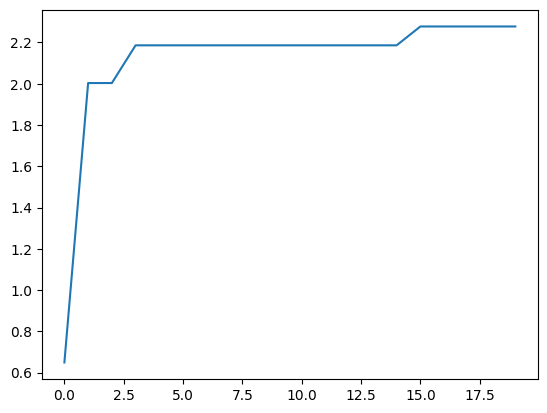

In [ ]:
import matplotlib.pyplot as plt
plt.plot(best_fitness)

In [ ]:
evaled_ind_list = list(evaled_ind.items())
evaled_ind_list.sort(key=lambda x: x[1], reverse=True)
for i in evaled_ind_list[:10]:
    print(i)

("['價格動量60', '價格波動率低', '月營收年增率10', '月營收月增率20', '交易活絡', '價格成交量背離', '月營收季節因子', 'MA反轉']", 2.2776356321116484)
("['價格動量60', '價格波動率低', '月營收年增率10', '月營收月增率20', '交易活絡', '月營收季節因子', 'MA反轉']", 2.186280986337162)
("['價格動量60', '價格波動率低', '月營收年增率10', '月營收月增率20', '交易活絡', '過去5天資金流入', '月營收季節因子', 'MA反轉']", 2.0513746779536257)
("['價格動量20', '價格動量60', '價格波動率低', '月營收年增率10', '月營收月增率20', '交易活絡', '價格成交量背離', '月營收季節因子', 'MA反轉']", 2.047417899159664)
("['價格動量20', '價格動量60', '價格波動率低', '月營收年增率10', '交易活絡', '月營收季節因子', 'MA反轉']", 2.003513638590951)
("['價格動量60', '價格波動率低', '月營收年增率10', '交易活絡', '月營收季節因子', 'MA反轉']", 1.8308957538361612)
("['價格動量60', '成交金額顯著增加', '價格波動率低', '月營收年增率10', '交易活絡', '過去5天資金流入', '月營收季節因子', 'MA反轉']", 1.8283279769959404)
("['價格動量60', '價格波動率低', '月營收月增率20', '交易活絡', '月營收季節因子', 'MA反轉']", 1.7018306347982526)
("['價格動量20', '價格動量60', '價格波動率低', '月營收年增率10', '月營收月增率20', '交易活絡', '月營收季節因子', 'MA反轉']", 1.652067234424025)
("['價格動量60', '成交金額顯著增加', '價格波動率低', '月營收年增率10', '月營收月增率20', '交易活絡', '月營收季節因子', 'MA反轉']", 1.6368369630